# Internal grasp force: standard vs. advanced model

The controller (`_compute_grasp_force_from_matrix`) builds the grasp matrix $G$ and optimizes
the contact forces subject to the friction cone. On top of that base optimization, two separate
effects are applied to get the force actually commanded to the gripper:

1. **Dynamic acceleration term**: the external wrench includes not only gravity ($mg$) but also
   $mass \times a_{max}$, the robot's maximum linear acceleration, to stay grasp-stable during
   motion, not just while static.
2. **Force clamping (20–140 N)**: if the raw optimized force falls outside the gripper's practical operating limits, it is clamped to strictly remain within the 20 N to 140 N range.

This notebook compares:
- **Standard**: gravity only in the wrench, no force floor (the raw, unclamped optimizer output).
- **Advanced**: gravity + acceleration term in the wrench, with the resulting force clamped to the 20–140 N bounds

Use the **friction slider** to see how both curves move as the object/gripper friction changes.


In [1]:
import numpy as np
import scipy.linalg
import scipy.optimize
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

np.set_printoptions(precision=3, suppress=True)


## Grasp-force model

This is the standalone version of `_compute_grasp_force_from_matrix` function. It builds the two-contact grasp matrix,
optionally adds `mass * max_accel` to the wrench (dynamic term), finds the minimum-norm contact
forces that satisfy the friction cone, and optionally clamps the result between `min_force` and `max_force`.


In [2]:
def skew(p):
    return np.array([[0, -p[2], p[1]], [p[2], 0, -p[0]], [-p[1], p[0], 0]])


def grasp_force(mass, obj_mu, gripper_mu=3.5, r=0.025, distance_z=0.05,
                 max_accel=5.0, gravity=9.81, min_force=20.0, max_force=140.0,
                 include_accel=True, apply_force_floor=True):
    mu_safe = max(np.sqrt(obj_mu * gripper_mu), 1e-6)

    p1 = np.array([0, -r, distance_z])
    p2 = np.array([0, r, distance_z])

    R1 = np.array([[1, 0, 0], 
                   [0, 0, -1], 
                   [0, 1, 0]])
    
    R2 = np.array([[0, 1, 0], 
                   [0, 0, 1], 
                   [1, 0, 0]])
    
    twist = np.array([[1, 0, 0, 0], 
                      [0, 1, 0, 0], 
                      [0, 0, 1, 0],
                      [0, 0, 0, 0], 
                      [0, 0, 0, 0], 
                      [0, 0, 0, 1]])

    Ad1 = np.block([[R1, np.zeros((3, 3))], 
                    [skew(p1) @ R1, R1]])
    
    Ad2 = np.block([[R2, np.zeros((3, 3))], 
                    [skew(p2) @ R2, R2]])
    
    G = np.hstack([Ad1 @ twist, Ad2 @ twist])
    G_inv = np.linalg.pinv(G)


    if include_accel:
        f_vel = mass * max_accel    # dynamic term (robot's max accel)
    else:
        f_vel = 0.0

    W = np.array([f_vel, f_vel, mass * gravity + f_vel, 0, 0, 0])
    f_ext = G_inv @ W
    N = scipy.linalg.null_space(G)

    def constraints(lam):
        f = f_ext + N @ lam
        f_t1, f_n1, tau1 = np.hypot(f[0], f[1]), f[2], abs(f[3])
        f_t2, f_n2, tau2 = np.hypot(f[4], f[5]), f[6], abs(f[7])
        gamma, min_normal = 0.01, 0.5
        return np.array([f_n1 - min_normal, f_n2 - min_normal,
                          mu_safe * f_n1 - f_t1 - gamma * tau1,
                          mu_safe * f_n2 - f_t2 - gamma * tau2])

    res = scipy.optimize.minimize(lambda lam: np.sum(lam ** 2), np.zeros(N.shape[1]),
                                   constraints={'type': 'ineq', 'fun': constraints})
    f_opt = f_ext + N @ res.x
    raw_force = max(f_opt[2], f_opt[6]) * 2.0

    if apply_force_floor:
        raw_force = np.clip(raw_force, min_force, max_force)          # clamp

    return dict(raw_force=raw_force, feasible=raw_force <= max_force)


## Interactive: force vs. mass, at a chosen friction coefficient
In this section it is possible to compare the standard model described in the book "A Mathematical
Introduction to Robotic Manipulation" (Murray, Li, Sastry) with the advanced model that take in accountant the dynamic model (acceleration of the manipulator) and the physical limits o of the gripper.

It is possible to drag the slider to sweep the (object) static-friction coefficient from glass-like (0.2) to rubber-like (0.9) and see how the **standard** and **advanced** curves shift across the experimental mass range (0.05-1.95 kg).


In [3]:
masses = np.linspace(0.05, 1.95, 40)

def plot_for_mu(mu=0.5):
    standard = [grasp_force(m, mu, include_accel=False, apply_force_floor=False)["raw_force"]
                for m in masses]
    clamped = [grasp_force(m, mu, include_accel=True, apply_force_floor=True)["raw_force"]
               for m in masses]

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(masses, standard, '--', label="Standard (gravity only, no floor)", color="tab:blue")
    ax.plot(masses, clamped, label="Advanced (+ max accel, 20N - 140N)", color="tab:orange")
    ax.axhline(20.0, color="gray", ls=":", lw=1, label="Gripper min force (20 N)")
    ax.set_xlabel("Object mass (kg)")
    ax.set_ylabel("Required contact force (N)")
    ax.set_title(f"\u03bc = {mu:.2f}")
    ax.legend(fontsize=8)
    ax.set_ylim(0, 60)
    plt.tight_layout()
    plt.show()

interact(plot_for_mu, mu=FloatSlider(value=0.4, min=0.2, max=0.9, step=0.05,
                                      description="friction \u03bc", continuous_update=False))


interactive(children=(FloatSlider(value=0.4, continuous_update=False, description='friction μ', max=0.9, min=0…

<function __main__.plot_for_mu(mu=0.5)>

## Heatmap: force vs. mass and friction

A 2D view of the raw advanced model output (gravity + max acceleration, **no 20 N floor**) across
the full experimental grid: object mass (0.05-1.95 kg) on the x-axis and friction coefficient
(0.2-0.9) on the y-axis. This is the surface the single-mu slider plot above is slicing through,
before the 20 N clamp is applied. It shows where the floor actually kicks in (most of the
grid, since the raw force stays below 20 N except at high mass / low friction).

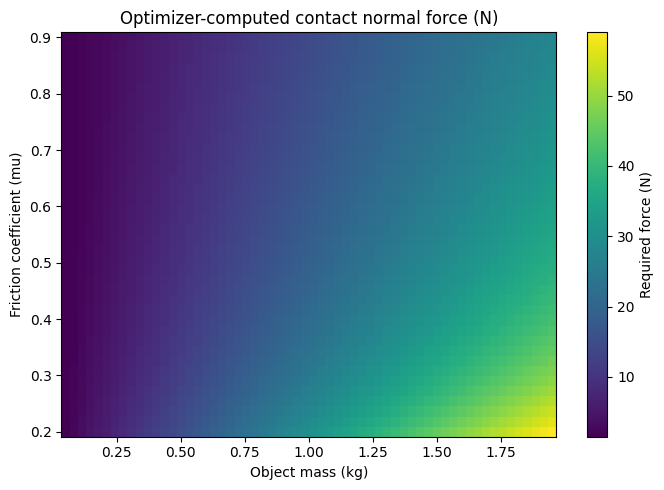

In [4]:
masses_grid = np.linspace(0.05, 1.95, 60)
mus_grid = np.linspace(0.2, 0.9, 40)

Z = np.zeros((len(mus_grid), len(masses_grid)))
for i, mu in enumerate(mus_grid):
    for j, m in enumerate(masses_grid):
        Z[i, j] = grasp_force(m, mu, include_accel=True, apply_force_floor=False)["raw_force"]

fig, ax = plt.subplots(figsize=(7, 5))
c = ax.pcolormesh(masses_grid, mus_grid, Z, cmap="viridis", shading="auto")
ax.set_xlabel("Object mass (kg)")
ax.set_ylabel("Friction coefficient (mu)")
ax.set_title("Optimizer-computed contact normal force (N)")
fig.colorbar(c, ax=ax, label="Required force (N)")
plt.tight_layout()
plt.show()


## Takeaway

The **clamped** curve sits at or above the **standard** curve everywhere: the dynamic
acceleration term adds `mass * max_accel` to the wrench regardless of friction, and the 20 N
floor pulls up any case where the raw optimized force would otherwise be lower (mostly at low
mass, where gravity alone demands very little force). The gap from the floor is largest at
**low mass** — that's where the raw, unclamped force actually dips under the gripper's practical
minimum. The gap from the acceleration term is roughly constant across mass since it scales
with mass in exactly the same way gravity does, so it doesn't change the *shape* of the curve,
just shifts it up. Neither effect depends strongly on friction — dragging the slider changes the
denominator ($\mu_{safe}$) but the relative standard-vs-clamped gap stays similar.
